In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

print("KPI analysis libraries imported successfully.")

KPI analysis libraries imported successfully.


In [2]:
# Step 4.1 — Configure project paths

project_root = Path.cwd()

if not (project_root / "data" / "interim").is_dir():
    project_root = project_root.parent

interim_path = project_root / "data" / "interim"
processed_path = project_root / "data" / "processed"

assert interim_path.is_dir(), "Interim data folder not found."

print("Project root:", project_root)
print("Interim data:", interim_path)
print("Processed data:", processed_path)

Project root: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics
Interim data: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\data\interim
Processed data: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\data\processed


In [3]:
# Load five cleaned datasets

datasets = {
    "plans": pd.read_csv(interim_path / "plans_cleaned.csv"),
    "customers": pd.read_csv(interim_path / "customers_cleaned.csv"),
    "subscriptions": pd.read_csv(
        interim_path / "subscriptions_cleaned.csv"
    ),
    "subscription_months": pd.read_csv(
        interim_path / "subscription_months_cleaned.csv"
    ),
    "invoices": pd.read_csv(interim_path / "invoices_cleaned.csv")
}

print("KPI DATASETS LOADED")
print("=" * 55)

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

KPI DATASETS LOADED
plans: 10 rows, 11 columns
customers: 1200 rows, 12 columns
subscriptions: 1381 rows, 12 columns
subscription_months: 19015 rows, 15 columns
invoices: 11257 rows, 17 columns


In [4]:
# Prepare monthly subscription data

monthly_df = datasets["subscription_months"].copy()

monthly_df["period_month"] = pd.to_datetime(
    monthly_df["period_month"],
    format="%Y-%m-%d",
    errors="coerce"
)

monthly_df["analysis_month"] = (
    monthly_df["period_month"].dt.to_period("M")
)

print("MONTHLY REVENUE DATA")
print("=" * 60)

print("Records:", len(monthly_df))
print("First month:", monthly_df["analysis_month"].min())
print("Last month:", monthly_df["analysis_month"].max())
print("Unique months:", monthly_df["analysis_month"].nunique())
print("Invalid dates:", monthly_df["period_month"].isna().sum())

MONTHLY REVENUE DATA
Records: 19015
First month: 2024-01
Last month: 2026-06
Unique months: 30
Invalid dates: 0


In [5]:
# Validate revenue columns

revenue_columns = [
    "mrr_usd",
    "previous_mrr_usd",
    "mrr_delta_usd"
]

validation_results = []

for column in revenue_columns:

    validation_results.append({
        "Column": column,
        "Data_Type": str(monthly_df[column].dtype),
        "Is_Numeric": pd.api.types.is_numeric_dtype(
            monthly_df[column]
        ),
        "Missing_Values": int(monthly_df[column].isna().sum()),
        "Negative_Values": int((monthly_df[column] < 0).sum())
    })

revenue_validation = pd.DataFrame(validation_results)

print("MRR COLUMN VALIDATION")
print("=" * 80)

print(revenue_validation.to_string(index=False))

MRR COLUMN VALIDATION
          Column Data_Type  Is_Numeric  Missing_Values  Negative_Values
         mrr_usd   float64        True               0                0
previous_mrr_usd   float64        True               0                0
   mrr_delta_usd   float64        True               0              626


In [6]:
# Verify MRR delta consistency

calculated_delta = (
    monthly_df["mrr_usd"]
    - monthly_df["previous_mrr_usd"]
)

delta_mismatches = (
    (
        calculated_delta
        - monthly_df["mrr_delta_usd"]
    ).abs() > 0.01
).sum()

print("MRR DELTA VALIDATION")
print("=" * 60)

print("Records checked:", len(monthly_df))
print("Delta mismatches:", delta_mismatches)

MRR DELTA VALIDATION
Records checked: 19015
Delta mismatches: 0


In [7]:
# Step 4.1 — Final validation

records_pass = len(monthly_df) == 19015

dates_pass = monthly_df["period_month"].notna().all()

numeric_pass = revenue_validation["Is_Numeric"].all()

missing_pass = (
    revenue_validation["Missing_Values"].sum() == 0
)

nonnegative_mrr_pass = (
    (monthly_df["mrr_usd"] >= 0).all()
    and (monthly_df["previous_mrr_usd"] >= 0).all()
)

delta_pass = delta_mismatches == 0

print("STEP 4.1 — FINAL VALIDATION")
print("=" * 60)

print("Record count:", records_pass)
print("Dates valid:", dates_pass)
print("Revenue columns numeric:", numeric_pass)
print("No missing revenue values:", missing_pass)
print("Current/previous MRR nonnegative:", nonnegative_mrr_pass)
print("MRR delta formula:", delta_pass)

if all([
    records_pass,
    dates_pass,
    numeric_pass,
    missing_pass,
    nonnegative_mrr_pass,
    delta_pass
]):
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

STEP 4.1 — FINAL VALIDATION
Record count: True
Dates valid: True
Revenue columns numeric: True
No missing revenue values: True
Current/previous MRR nonnegative: True
MRR delta formula: True

RESULT: PASS


In [8]:
# Step 4.2.2 — Calculate Monthly Recurring Revenue

monthly_mrr = (
    monthly_df
    .groupby("analysis_month")
    .agg(
        Total_MRR_USD=("mrr_usd", "sum"),
        Monthly_Records=("mrr_usd", "size")
    )
    .reset_index()
    .sort_values("analysis_month")
)

monthly_mrr["Total_MRR_USD"] = (
    monthly_mrr["Total_MRR_USD"].round(2)
)

print("MONTHLY RECURRING REVENUE")
print("=" * 70)

print(monthly_mrr.to_string(index=False))

print("\nMonths analyzed:", len(monthly_mrr))

MONTHLY RECURRING REVENUE
analysis_month  Total_MRR_USD  Monthly_Records
       2024-01      145853.24              464
       2024-02      151051.80              481
       2024-03      155769.21              477
       2024-04      163530.40              477
       2024-05      171524.29              486
       2024-06      177113.30              489
       2024-07      185335.76              495
       2024-08      192664.71              503
       2024-09      201173.32              523
       2024-10      206885.58              527
       2024-11      224222.88              544
       2024-12      232399.74              562
       2025-01      243134.78              584
       2025-02      252213.10              593
       2025-03      269714.65              604
       2025-04      284555.85              623
       2025-05      302151.48              646
       2025-06      309980.58              667
       2025-07      320486.34              677
       2025-08      329661.03     

In [9]:
# Step 4.2.3 — Validate Monthly MRR

source_mrr = monthly_df["mrr_usd"].sum()
aggregated_mrr = monthly_mrr["Total_MRR_USD"].sum()

record_count_pass = (
    monthly_mrr["Monthly_Records"].sum()
    == len(monthly_df)
)

revenue_match_pass = np.isclose(
    source_mrr,
    aggregated_mrr,
    atol=0.01,
    rtol=0
)

unique_months_pass = (
    len(monthly_mrr)
    == monthly_df["analysis_month"].nunique()
)

print("MONTHLY MRR VALIDATION")
print("=" * 65)

print("Source MRR sum:", round(source_mrr, 2))
print("Aggregated MRR sum:", round(aggregated_mrr, 2))
print("Record counts match:", record_count_pass)
print("Revenue totals match:", revenue_match_pass)
print("Unique months match:", unique_months_pass)

if all([
    record_count_pass,
    revenue_match_pass,
    unique_months_pass
]):
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

MONTHLY MRR VALIDATION
Source MRR sum: 8531565.48
Aggregated MRR sum: 8531565.48
Record counts match: True
Revenue totals match: True
Unique months match: True

RESULT: PASS


In [10]:
# Step 4.2.4 — Month-over-Month MRR Growth

monthly_mrr["Previous_Month_MRR"] = (
    monthly_mrr["Total_MRR_USD"].shift(1)
)

monthly_mrr["MRR_Change_USD"] = (
    monthly_mrr["Total_MRR_USD"]
    - monthly_mrr["Previous_Month_MRR"]
)

monthly_mrr["MRR_Growth_Pct"] = np.where(
    monthly_mrr["Previous_Month_MRR"] > 0,
    (
        monthly_mrr["MRR_Change_USD"]
        / monthly_mrr["Previous_Month_MRR"]
    ) * 100,
    np.nan
)

monthly_mrr["MRR_Growth_Pct"] = (
    monthly_mrr["MRR_Growth_Pct"].round(2)
)

print("MONTHLY MRR GROWTH ANALYSIS")
print("=" * 90)

print(
    monthly_mrr[
        [
            "analysis_month",
            "Total_MRR_USD",
            "Previous_Month_MRR",
            "MRR_Change_USD",
            "MRR_Growth_Pct"
        ]
    ].to_string(index=False)
)

MONTHLY MRR GROWTH ANALYSIS
analysis_month  Total_MRR_USD  Previous_Month_MRR  MRR_Change_USD  MRR_Growth_Pct
       2024-01      145853.24                 NaN             NaN             NaN
       2024-02      151051.80           145853.24         5198.56            3.56
       2024-03      155769.21           151051.80         4717.41            3.12
       2024-04      163530.40           155769.21         7761.19            4.98
       2024-05      171524.29           163530.40         7993.89            4.89
       2024-06      177113.30           171524.29         5589.01            3.26
       2024-07      185335.76           177113.30         8222.46            4.64
       2024-08      192664.71           185335.76         7328.95            3.95
       2024-09      201173.32           192664.71         8508.61            4.42
       2024-10      206885.58           201173.32         5712.26            2.84
       2024-11      224222.88           206885.58        17337.30     

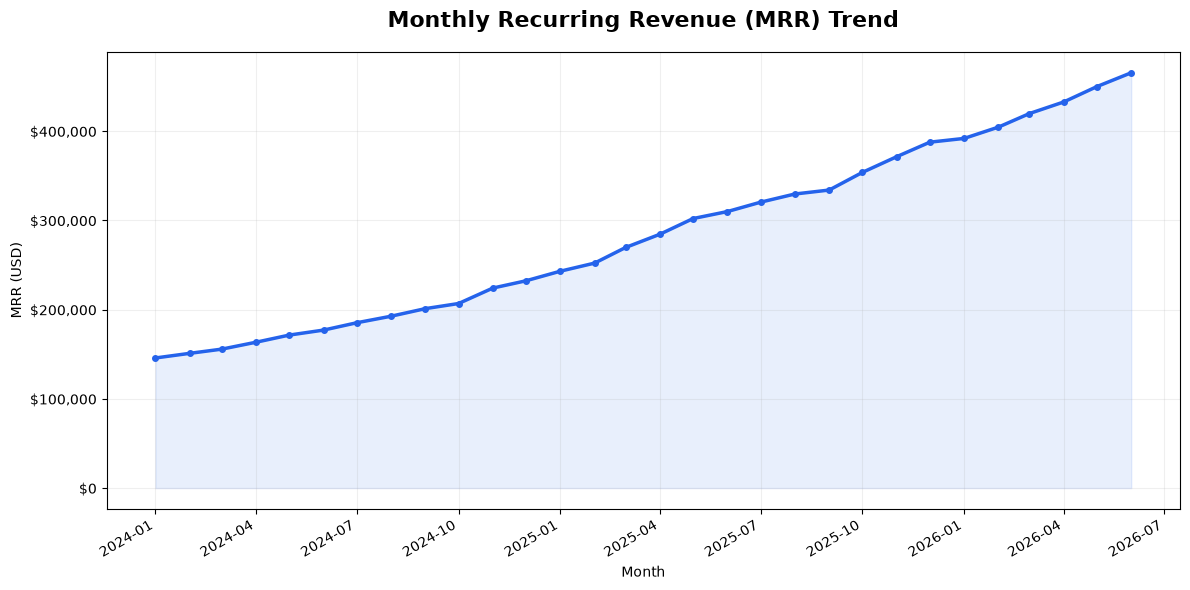

In [11]:
# Step 4.2.5 — Monthly MRR Trend Visualization

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from pathlib import Path

figures_path = project_root / "reports" / "figures"
figures_path.mkdir(parents=True, exist_ok=True)

plot_data = monthly_mrr.copy()

plot_data["Month"] = (
    plot_data["analysis_month"].dt.to_timestamp()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    plot_data["Month"],
    plot_data["Total_MRR_USD"],
    marker="o",
    markersize=4,
    linewidth=2.5,
    color="#2563EB"
)

ax.fill_between(
    plot_data["Month"],
    plot_data["Total_MRR_USD"],
    alpha=0.10,
    color="#2563EB"
)

ax.set_title(
    "Monthly Recurring Revenue (MRR) Trend",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("MRR (USD)")

ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("${x:,.0f}")
)

ax.grid(alpha=0.2)

fig.autofmt_xdate()
plt.tight_layout()

plt.savefig(
    figures_path / "monthly_mrr_trend.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Step 4.2.6 — MRR Business Findings

highest_mrr = monthly_mrr.loc[
    monthly_mrr["Total_MRR_USD"].idxmax()
]

lowest_mrr = monthly_mrr.loc[
    monthly_mrr["Total_MRR_USD"].idxmin()
]

latest_mrr = monthly_mrr.iloc[-1]

valid_growth = monthly_mrr.dropna(
    subset=["MRR_Growth_Pct"]
)

print("MRR BUSINESS FINDINGS")
print("=" * 75)

print(
    "Highest MRR month:",
    highest_mrr["analysis_month"],
    "| MRR: $",
    f"{highest_mrr['Total_MRR_USD']:,.2f}"
)

print(
    "Lowest MRR month:",
    lowest_mrr["analysis_month"],
    "| MRR: $",
    f"{lowest_mrr['Total_MRR_USD']:,.2f}"
)

print(
    "Latest month:",
    latest_mrr["analysis_month"],
    "| MRR: $",
    f"{latest_mrr['Total_MRR_USD']:,.2f}"
)

if not valid_growth.empty:

    highest_growth = valid_growth.loc[
        valid_growth["MRR_Growth_Pct"].idxmax()
    ]

    print(
        "Highest MoM MRR growth:",
        highest_growth["analysis_month"],
        "| Growth:",
        f"{highest_growth['MRR_Growth_Pct']:.2f}%"
    )

MRR BUSINESS FINDINGS
Highest MRR month: 2026-06 | MRR: $ 465,561.26
Lowest MRR month: 2024-01 | MRR: $ 145,853.24
Latest month: 2026-06 | MRR: $ 465,561.26
Highest MoM MRR growth: 2024-11 | Growth: 8.38%


In [13]:
# Step 4.2.7 — Final MRR Validation

mrr_nonnegative = (
    monthly_mrr["Total_MRR_USD"] >= 0
).all()

months_match = (
    len(monthly_mrr)
    == monthly_df["analysis_month"].nunique()
)

chart_file = figures_path / "monthly_mrr_trend.png"

chart_saved = (
    chart_file.is_file()
    and chart_file.stat().st_size > 0
)

print("STEP 4.2 — FINAL VALIDATION")
print("=" * 60)

print("Record counts match:", record_count_pass)
print("Revenue totals match:", revenue_match_pass)
print("Monthly MRR nonnegative:", mrr_nonnegative)
print("Unique months match:", months_match)
print("MRR chart saved:", chart_saved)

if all([
    record_count_pass,
    revenue_match_pass,
    mrr_nonnegative,
    months_match,
    chart_saved
]):
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

STEP 4.2 — FINAL VALIDATION
Record counts match: True
Revenue totals match: True
Monthly MRR nonnegative: True
Unique months match: True
MRR chart saved: True

RESULT: PASS


In [14]:
# Step 4.3.2 — Movement category validation

expected_movements = {
    "New",
    "Expansion",
    "Contraction",
    "Churn",
    "Reactivation",
    "Retained"
}

actual_movements = set(
    monthly_df["movement_type"].dropna().unique()
)

unknown_movements = actual_movements - expected_movements
missing_movement_rows = monthly_df["movement_type"].isna().sum()

print("MRR MOVEMENT VALIDATION")
print("=" * 60)

print("Movement categories:", sorted(actual_movements))
print("Unknown categories:", unknown_movements)
print("Missing movement rows:", missing_movement_rows)

assert not unknown_movements
assert missing_movement_rows == 0

print("\nRESULT: PASS")

MRR MOVEMENT VALIDATION
Movement categories: ['Churn', 'Contraction', 'Expansion', 'New', 'Reactivation', 'Retained']
Unknown categories: set()
Missing movement rows: 0

RESULT: PASS


In [15]:
# Step 4.3.3 — Calculate monthly MRR movements

movement_mrr = (
    monthly_df
    .groupby(["analysis_month", "movement_type"])["mrr_delta_usd"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        columns=[
            "New",
            "Expansion",
            "Contraction",
            "Churn",
            "Reactivation",
            "Retained"
        ],
        fill_value=0
    )
    .reset_index()
)

movement_mrr = movement_mrr.rename(columns={
    "New": "New_MRR",
    "Expansion": "Expansion_MRR",
    "Contraction": "Contraction_MRR_Signed",
    "Churn": "Churn_MRR_Signed",
    "Reactivation": "Reactivation_MRR",
    "Retained": "Retained_MRR_Change"
})

# Report losses as positive magnitudes
movement_mrr["Contraction_MRR"] = (
    -movement_mrr["Contraction_MRR_Signed"]
)

movement_mrr["Churn_MRR"] = (
    -movement_mrr["Churn_MRR_Signed"]
)

movement_mrr["Net_MRR_Change"] = (
    movement_mrr["New_MRR"]
    + movement_mrr["Expansion_MRR"]
    + movement_mrr["Reactivation_MRR"]
    - movement_mrr["Contraction_MRR"]
    - movement_mrr["Churn_MRR"]
    + movement_mrr["Retained_MRR_Change"]
)

print("MONTHLY MRR MOVEMENTS")
print("=" * 110)

print(movement_mrr.to_string(index=False))

MONTHLY MRR MOVEMENTS
analysis_month   New_MRR  Expansion_MRR  Contraction_MRR_Signed  Churn_MRR_Signed  Reactivation_MRR  Retained_MRR_Change  Contraction_MRR  Churn_MRR  Net_MRR_Change
       2024-01 145853.24           0.00                    0.00              0.00              0.00                  0.0            -0.00      -0.00       145853.24
       2024-02   6830.65        1276.20                 -615.40          -2292.89              0.00                  0.0           615.40    2292.89         5198.56
       2024-03   2047.34        5748.80                 -279.40          -2799.33              0.00                  0.0           279.40    2799.33         4717.41
       2024-04   5965.74        4819.65                 -375.20          -2649.00              0.00                  0.0           375.20    2649.00         7761.19
       2024-05   3828.17        6698.50                 -204.00          -2328.78              0.00                  0.0           204.00    2328.78     

In [16]:
# Step 4.3.4 — Validate movement signs

sign_checks = {
    "New MRR nonnegative":
        (movement_mrr["New_MRR"] >= -0.01).all(),

    "Expansion MRR nonnegative":
        (movement_mrr["Expansion_MRR"] >= -0.01).all(),

    "Reactivation MRR nonnegative":
        (movement_mrr["Reactivation_MRR"] >= -0.01).all(),

    "Contraction loss nonnegative":
        (movement_mrr["Contraction_MRR"] >= -0.01).all(),

    "Churn loss nonnegative":
        (movement_mrr["Churn_MRR"] >= -0.01).all(),

    "Retained movement approximately zero":
        (movement_mrr["Retained_MRR_Change"].abs() <= 0.01).all()
}

print("MRR MOVEMENT SIGN VALIDATION")
print("=" * 65)

for check, passed in sign_checks.items():
    print(f"{check}: {bool(passed)}")

print(
    "\nRESULT:",
    "PASS" if all(sign_checks.values()) else "REVIEW REQUIRED"
)

MRR MOVEMENT SIGN VALIDATION
New MRR nonnegative: True
Expansion MRR nonnegative: True
Reactivation MRR nonnegative: True
Contraction loss nonnegative: True
Churn loss nonnegative: True
Retained movement approximately zero: True

RESULT: PASS


In [17]:
# Step 4.3.5 — Reconcile movement totals with MRR change

mrr_reconciliation = monthly_mrr[
    ["analysis_month", "Total_MRR_USD"]
].merge(
    movement_mrr[
        ["analysis_month", "Net_MRR_Change"]
    ],
    on="analysis_month",
    how="outer",
    validate="one_to_one",
    indicator=True
).sort_values("analysis_month").reset_index(drop=True)

mrr_reconciliation["Previous_Month_MRR"] = (
    mrr_reconciliation["Total_MRR_USD"].shift(1)
)

mrr_reconciliation["Actual_MRR_Change"] = (
    mrr_reconciliation["Total_MRR_USD"]
    - mrr_reconciliation["Previous_Month_MRR"]
)

mrr_reconciliation["Reconciliation_Difference"] = (
    mrr_reconciliation["Actual_MRR_Change"]
    - mrr_reconciliation["Net_MRR_Change"]
)

# First month has no observed previous-month MRR.
comparable_months = mrr_reconciliation[
    mrr_reconciliation["Previous_Month_MRR"].notna()
].copy()

mismatch_count = (
    comparable_months["Reconciliation_Difference"].abs() > 0.01
).sum()

print("MRR MOVEMENT RECONCILIATION")
print("=" * 110)

print(
    mrr_reconciliation[
        [
            "analysis_month",
            "Total_MRR_USD",
            "Actual_MRR_Change",
            "Net_MRR_Change",
            "Reconciliation_Difference"
        ]
    ].to_string(index=False)
)

print("\nUnmatched months:",
      (mrr_reconciliation["_merge"] != "both").sum())

print("Comparable months:", len(comparable_months))
print("Reconciliation mismatches:", int(mismatch_count))

MRR MOVEMENT RECONCILIATION
analysis_month  Total_MRR_USD  Actual_MRR_Change  Net_MRR_Change  Reconciliation_Difference
       2024-01      145853.24                NaN       145853.24                        NaN
       2024-02      151051.80            5198.56         5198.56              -3.637979e-12
       2024-03      155769.21            4717.41         4717.41               2.728484e-12
       2024-04      163530.40            7761.19         7761.19               3.637979e-12
       2024-05      171524.29            7993.89         7993.89               1.455192e-11
       2024-06      177113.30            5589.01         5589.01              -1.909939e-11
       2024-07      185335.76            8222.46         8222.46               2.000888e-11
       2024-08      192664.71            7328.95         7328.95              -1.818989e-11
       2024-09      201173.32            8508.61         8508.61               1.455192e-11
       2024-10      206885.58            5712.26    

In [18]:
# Step 4.3.6 — Source delta reconciliation

source_delta = (
    monthly_df
    .groupby("analysis_month")["mrr_delta_usd"]
    .sum()
    .rename("Source_Net_Delta")
    .reset_index()
)

delta_validation = movement_mrr[
    ["analysis_month", "Net_MRR_Change"]
].merge(
    source_delta,
    on="analysis_month",
    validate="one_to_one"
)

delta_validation["Difference"] = (
    delta_validation["Net_MRR_Change"]
    - delta_validation["Source_Net_Delta"]
)

delta_pass = (
    delta_validation["Difference"].abs() <= 0.01
).all()

print("SOURCE DELTA VALIDATION")
print("=" * 65)

print("Monthly movement sums match source deltas:", bool(delta_pass))
print("Maximum absolute difference:",
      delta_validation["Difference"].abs().max())

print("\nRESULT:", "PASS" if delta_pass else "REVIEW REQUIRED")

SOURCE DELTA VALIDATION
Monthly movement sums match source deltas: True
Maximum absolute difference: 3.637978807091713e-12

RESULT: PASS


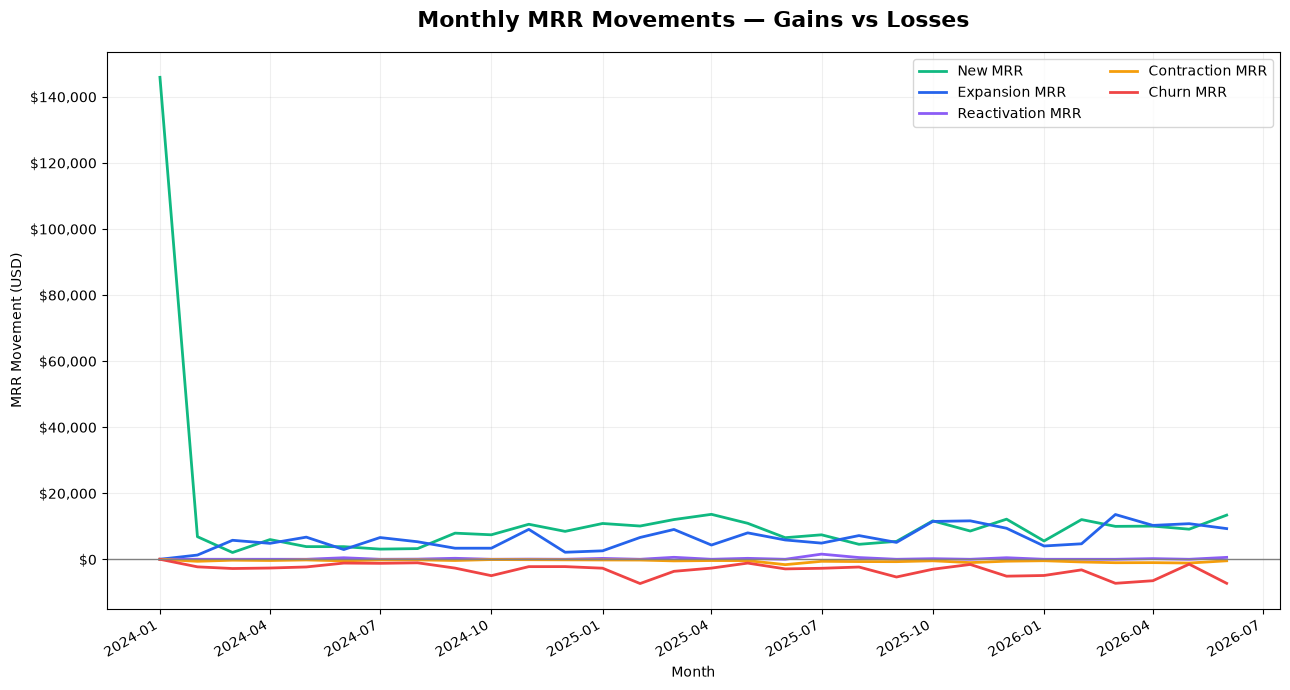

In [19]:
# Step 4.3.7 — MRR movement visualization

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plot_data = movement_mrr.copy()
plot_data["Month"] = plot_data["analysis_month"].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 7))

movement_series = {
    "New MRR": ("New_MRR", "#10B981"),
    "Expansion MRR": ("Expansion_MRR", "#2563EB"),
    "Reactivation MRR": ("Reactivation_MRR", "#8B5CF6"),
    "Contraction MRR": ("Contraction_MRR", "#F59E0B"),
    "Churn MRR": ("Churn_MRR", "#EF4444")
}

for label, (column, color) in movement_series.items():
    values = plot_data[column]

    if column in ["Contraction_MRR", "Churn_MRR"]:
        values = -values

    ax.plot(
        plot_data["Month"],
        values,
        linewidth=2,
        label=label,
        color=color
    )

ax.axhline(0, color="gray", linewidth=1)

ax.set_title(
    "Monthly MRR Movements — Gains vs Losses",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("MRR Movement (USD)")

ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("${x:,.0f}")
)

ax.grid(alpha=0.2)
ax.legend(ncol=2)

fig.autofmt_xdate()
plt.tight_layout()

chart_path = figures_path / "monthly_mrr_movements.png"

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Step 4.3.8 — Final validation

categories_pass = (
    not unknown_movements
    and missing_movement_rows == 0
)

signs_pass = all(sign_checks.values())

source_pass = bool(delta_pass)

bridge_pass = (
    (mrr_reconciliation["_merge"] == "both").all()
    and len(comparable_months) > 0
    and mismatch_count == 0
)

chart_pass = (
    chart_path.is_file()
    and chart_path.stat().st_size > 0
)

print("STEP 4.3 — FINAL VALIDATION")
print("=" * 65)

print("Movement categories:", categories_pass)
print("Movement signs:", signs_pass)
print("Source delta reconciliation:", source_pass)
print("MRR closing balance reconciliation:", bridge_pass)
print("Movement chart saved:", chart_pass)

if all([
    categories_pass,
    signs_pass,
    source_pass,
    bridge_pass,
    chart_pass
]):
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

STEP 4.3 — FINAL VALIDATION
Movement categories: True
Movement signs: True
Source delta reconciliation: True
MRR closing balance reconciliation: True
Movement chart saved: True

RESULT: PASS


In [21]:
# Step 4.4.2 — Monthly subscription churn events

monthly_churn_events = (
    monthly_df
    .assign(
        Is_Churn=monthly_df["movement_type"].eq("Churn")
    )
    .groupby("analysis_month")
    .agg(
        Churn_Records=("Is_Churn", "sum"),
        Total_Monthly_Records=("Is_Churn", "size")
    )
    .reset_index()
    .sort_values("analysis_month")
)

print("MONTHLY SUBSCRIPTION CHURN EVENTS")
print("=" * 75)

print(monthly_churn_events.to_string(index=False))

print(
    "\nTotal churn records:",
    monthly_churn_events["Churn_Records"].sum()
)

MONTHLY SUBSCRIPTION CHURN EVENTS
analysis_month  Churn_Records  Total_Monthly_Records
       2024-01              0                    464
       2024-02             13                    481
       2024-03             14                    477
       2024-04             12                    477
       2024-05             12                    486
       2024-06              9                    489
       2024-07              9                    495
       2024-08              8                    503
       2024-09             14                    523
       2024-10             14                    527
       2024-11             10                    544
       2024-12             11                    562
       2025-01             12                    584
       2025-02             15                    593
       2025-03             13                    604
       2025-04             13                    623
       2025-05              8                    646
       2025-

In [22]:
# Step 4.4.3 — Customers with churn events

churn_rows = monthly_df[
    monthly_df["movement_type"] == "Churn"
].copy()

monthly_customer_churn_events = (
    churn_rows
    .groupby("analysis_month")["customer_id"]
    .nunique()
    .rename("Customers_With_Churn_Event")
    .reset_index()
)

monthly_churn_events = monthly_churn_events.merge(
    monthly_customer_churn_events,
    on="analysis_month",
    how="left",
    validate="one_to_one"
)

monthly_churn_events["Customers_With_Churn_Event"] = (
    monthly_churn_events["Customers_With_Churn_Event"]
    .fillna(0)
    .astype(int)
)

print("MONTHLY CHURN EVENTS — SUBSCRIPTIONS VS CUSTOMERS")
print("=" * 85)

print(
    monthly_churn_events[
        [
            "analysis_month",
            "Churn_Records",
            "Customers_With_Churn_Event"
        ]
    ].to_string(index=False)
)

MONTHLY CHURN EVENTS — SUBSCRIPTIONS VS CUSTOMERS
analysis_month  Churn_Records  Customers_With_Churn_Event
       2024-01              0                           0
       2024-02             13                          13
       2024-03             14                          14
       2024-04             12                          12
       2024-05             12                          12
       2024-06              9                           9
       2024-07              9                           9
       2024-08              8                           8
       2024-09             14                          14
       2024-10             14                          14
       2024-11             10                          10
       2024-12             11                          11
       2025-01             12                          12
       2025-02             15                          15
       2025-03             13                          13
       2025-04        

In [23]:
# Step 4.4.4 — Beginning-of-month paid subscription base

opening_subscription_base = (
    monthly_df
    .assign(
        Was_Paid_At_Start=monthly_df["previous_mrr_usd"] > 0
    )
    .loc[lambda df: df["Was_Paid_At_Start"]]
    .groupby("analysis_month")["subscription_id"]
    .nunique()
    .rename("Opening_Paid_Subscriptions")
    .reset_index()
)

monthly_churn_events = monthly_churn_events.merge(
    opening_subscription_base,
    on="analysis_month",
    how="left",
    validate="one_to_one"
)

monthly_churn_events["Opening_Paid_Subscriptions"] = (
    monthly_churn_events["Opening_Paid_Subscriptions"]
    .fillna(0)
    .astype(int)
)

print("OPENING PAID SUBSCRIPTION BASE")
print("=" * 80)

print(
    monthly_churn_events[
        [
            "analysis_month",
            "Opening_Paid_Subscriptions",
            "Churn_Records"
        ]
    ].to_string(index=False)
)

OPENING PAID SUBSCRIPTION BASE
analysis_month  Opening_Paid_Subscriptions  Churn_Records
       2024-01                           0              0
       2024-02                         464             13
       2024-03                         468             14
       2024-04                         463             12
       2024-05                         465             12
       2024-06                         474              9
       2024-07                         480              9
       2024-08                         486              8
       2024-09                         495             14
       2024-10                         509             14
       2024-11                         513             10
       2024-12                         534             11
       2025-01                         551             12
       2025-02                         572             15
       2025-03                         578             13
       2025-04                         59

In [24]:
# Step 4.4.5 — Subscription churn rate

monthly_churn_events["Subscription_Churn_Rate_Pct"] = np.where(
    monthly_churn_events["Opening_Paid_Subscriptions"] > 0,
    (
        monthly_churn_events["Churn_Records"]
        / monthly_churn_events["Opening_Paid_Subscriptions"]
    ) * 100,
    np.nan
)

monthly_churn_events["Subscription_Churn_Rate_Pct"] = (
    monthly_churn_events["Subscription_Churn_Rate_Pct"].round(2)
)

print("MONTHLY SUBSCRIPTION CHURN RATE")
print("=" * 95)

print(
    monthly_churn_events[
        [
            "analysis_month",
            "Opening_Paid_Subscriptions",
            "Churn_Records",
            "Subscription_Churn_Rate_Pct"
        ]
    ].to_string(index=False)
)

MONTHLY SUBSCRIPTION CHURN RATE
analysis_month  Opening_Paid_Subscriptions  Churn_Records  Subscription_Churn_Rate_Pct
       2024-01                           0              0                          NaN
       2024-02                         464             13                         2.80
       2024-03                         468             14                         2.99
       2024-04                         463             12                         2.59
       2024-05                         465             12                         2.58
       2024-06                         474              9                         1.90
       2024-07                         480              9                         1.88
       2024-08                         486              8                         1.65
       2024-09                         495             14                         2.83
       2024-10                         509             14                         2.75
       2024

In [25]:
# Step 4.4.6 — Churn validation

total_churn_pass = (
    monthly_churn_events["Churn_Records"].sum() == 368
)

customer_count_pass = (
    monthly_churn_events["Customers_With_Churn_Event"]
    <= monthly_churn_events["Churn_Records"]
).all()

churn_base_pass = (
    monthly_churn_events["Churn_Records"]
    <= monthly_churn_events["Opening_Paid_Subscriptions"]
).all()

valid_rate = monthly_churn_events[
    "Subscription_Churn_Rate_Pct"
].dropna()

rate_range_pass = valid_rate.between(0, 100).all()

print("CHURN CALCULATION VALIDATION")
print("=" * 65)

print("Total churn events match:", total_churn_pass)
print("Customer count <= churn events:", customer_count_pass)
print("Churn events <= opening paid base:", churn_base_pass)
print("Churn rates within 0–100%:", rate_range_pass)

if all([
    total_churn_pass,
    customer_count_pass,
    churn_base_pass,
    rate_range_pass
]):
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

CHURN CALCULATION VALIDATION
Total churn events match: True
Customer count <= churn events: True
Churn events <= opening paid base: True
Churn rates within 0–100%: True

RESULT: PASS


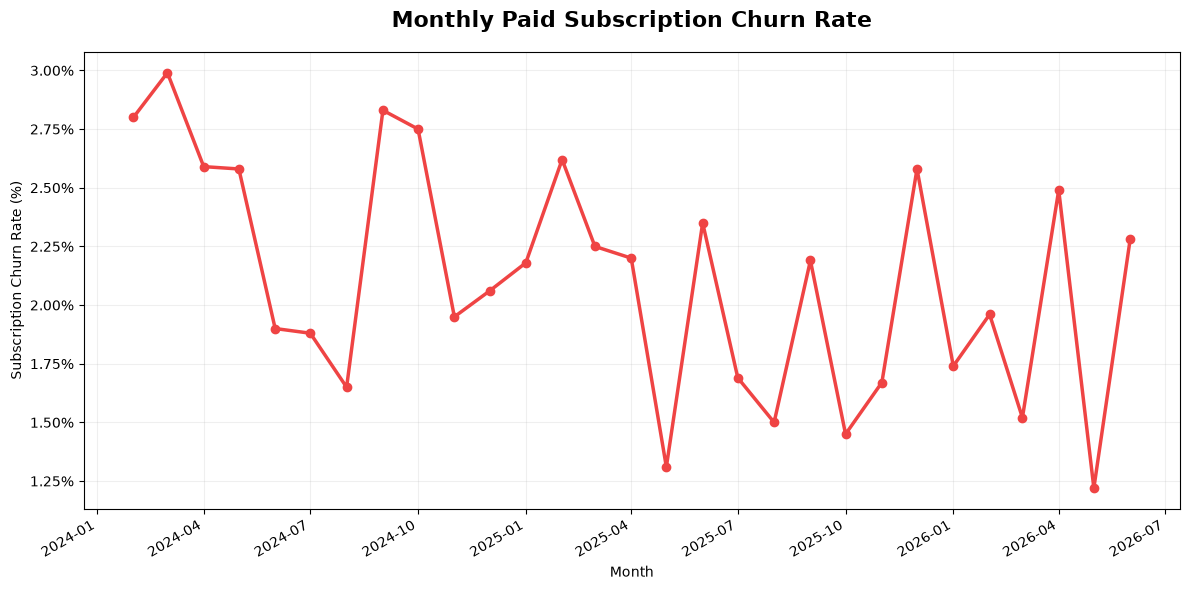

In [26]:
# Step 4.4.7 — Monthly subscription churn rate trend

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plot_data = monthly_churn_events.copy()

plot_data["Month"] = (
    plot_data["analysis_month"].dt.to_timestamp()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    plot_data["Month"],
    plot_data["Subscription_Churn_Rate_Pct"],
    marker="o",
    linewidth=2.5,
    color="#EF4444"
)

ax.set_title(
    "Monthly Paid Subscription Churn Rate",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Subscription Churn Rate (%)")

ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100)
)

ax.grid(alpha=0.2)

fig.autofmt_xdate()
plt.tight_layout()

chart_path = (
    figures_path / "monthly_subscription_churn_rate.png"
)

plt.savefig(
    chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Step 4.4.8 — Churn business findings

valid_months = monthly_churn_events.dropna(
    subset=["Subscription_Churn_Rate_Pct"]
)

print("SUBSCRIPTION CHURN FINDINGS")
print("=" * 70)

print(
    "Total churn movement records:",
    monthly_churn_events["Churn_Records"].sum()
)

print(
    "Months analyzed:",
    len(monthly_churn_events)
)

if not valid_months.empty:

    highest_churn_rate = valid_months.loc[
        valid_months["Subscription_Churn_Rate_Pct"].idxmax()
    ]

    lowest_churn_rate = valid_months.loc[
        valid_months["Subscription_Churn_Rate_Pct"].idxmin()
    ]

    print(
        "Highest churn-rate month:",
        highest_churn_rate["analysis_month"],
        "| Rate:",
        f"{highest_churn_rate['Subscription_Churn_Rate_Pct']:.2f}%"
    )

    print(
        "Lowest churn-rate month:",
        lowest_churn_rate["analysis_month"],
        "| Rate:",
        f"{lowest_churn_rate['Subscription_Churn_Rate_Pct']:.2f}%"
    )

SUBSCRIPTION CHURN FINDINGS
Total churn movement records: 368
Months analyzed: 30
Highest churn-rate month: 2024-03 | Rate: 2.99%
Lowest churn-rate month: 2026-05 | Rate: 1.22%


In [28]:
# Step 4.4.9 — Final churn validation

chart_saved = (
    chart_path.is_file()
    and chart_path.stat().st_size > 0
)

checks = {
    "Churn records": bool(total_churn_pass),
    "Customer-event counts": bool(customer_count_pass),
    "Opening base consistency": bool(churn_base_pass),
    "Churn-rate range": bool(rate_range_pass),
    "Chart saved": bool(chart_saved)
}

print("STEP 4.4 — FINAL VALIDATION")
print("=" * 65)

for name, passed in checks.items():
    print(f"{name}: {passed}")

print(
    "\nRESULT:",
    "PASS" if all(checks.values()) else "REVIEW REQUIRED"
)

STEP 4.4 — FINAL VALIDATION
Churn records: True
Customer-event counts: True
Opening base consistency: True
Churn-rate range: True
Chart saved: True

RESULT: PASS


In [29]:
# Step 4.5.2 — Prepare retention flags

retention_df = monthly_df.copy()

retention_df["Paid_At_Start"] = (
    retention_df["previous_mrr_usd"] > 0
)

retention_df["Paid_At_End"] = (
    retention_df["mrr_usd"] > 0
)

retention_df["Retained_Subscription"] = (
    retention_df["Paid_At_Start"]
    & retention_df["Paid_At_End"]
)

print("RETENTION FLAGS")
print("=" * 60)

print(
    retention_df[
        [
            "subscription_id",
            "analysis_month",
            "previous_mrr_usd",
            "mrr_usd",
            "Paid_At_Start",
            "Paid_At_End",
            "Retained_Subscription"
        ]
    ].head(10).to_string(index=False)
)

RETENTION FLAGS
subscription_id analysis_month  previous_mrr_usd  mrr_usd  Paid_At_Start  Paid_At_End  Retained_Subscription
      SUB-00001        2024-01              0.00   547.83          False         True                  False
      SUB-00001        2024-02            547.83   547.83           True         True                   True
      SUB-00001        2024-03            547.83   547.83           True         True                   True
      SUB-00001        2024-04            547.83   547.83           True         True                   True
      SUB-00001        2024-05            547.83   547.83           True         True                   True
      SUB-00001        2024-06            547.83   547.83           True         True                   True
      SUB-00001        2024-07            547.83   701.83           True         True                   True
      SUB-00001        2024-08            701.83   701.83           True         True                   True
   

In [30]:
# Step 4.5.3 — Monthly subscription retention

monthly_retention = (
    retention_df
    .groupby("analysis_month")
    .agg(
        Opening_Paid_Subscriptions=(
            "Paid_At_Start", "sum"
        ),
        Retained_Subscriptions=(
            "Retained_Subscription", "sum"
        ),
        Closing_Paid_Subscriptions=(
            "Paid_At_End", "sum"
        )
    )
    .reset_index()
    .sort_values("analysis_month")
)

monthly_retention["Subscription_Retention_Rate_Pct"] = (
    np.where(
        monthly_retention["Opening_Paid_Subscriptions"] > 0,
        (
            monthly_retention["Retained_Subscriptions"]
            / monthly_retention["Opening_Paid_Subscriptions"]
        ) * 100,
        np.nan
    )
)

monthly_retention["Subscription_Retention_Rate_Pct"] = (
    monthly_retention["Subscription_Retention_Rate_Pct"].round(2)
)

print("MONTHLY SUBSCRIPTION RETENTION")
print("=" * 90)

print(monthly_retention.to_string(index=False))

MONTHLY SUBSCRIPTION RETENTION
analysis_month  Opening_Paid_Subscriptions  Retained_Subscriptions  Closing_Paid_Subscriptions  Subscription_Retention_Rate_Pct
       2024-01                           0                       0                         464                              NaN
       2024-02                         464                     451                         468                            97.20
       2024-03                         468                     454                         463                            97.01
       2024-04                         463                     451                         465                            97.41
       2024-05                         465                     453                         474                            97.42
       2024-06                         474                     465                         480                            98.10
       2024-07                         480                     471       

In [31]:
# Step 4.5.4 — Customer-level paid retention

customer_month_status = (
    retention_df
    .groupby(["analysis_month", "customer_id"])
    .agg(
        Paid_At_Start=("Paid_At_Start", "max"),
        Paid_At_End=("Paid_At_End", "max")
    )
    .reset_index()
)

customer_month_status["Retained_Customer"] = (
    customer_month_status["Paid_At_Start"]
    & customer_month_status["Paid_At_End"]
)

monthly_customer_retention = (
    customer_month_status
    .groupby("analysis_month")
    .agg(
        Opening_Paid_Customers=("Paid_At_Start", "sum"),
        Retained_Customers=("Retained_Customer", "sum"),
        Closing_Paid_Customers=("Paid_At_End", "sum")
    )
    .reset_index()
)

monthly_customer_retention["Customer_Retention_Rate_Pct"] = (
    np.where(
        monthly_customer_retention["Opening_Paid_Customers"] > 0,
        (
            monthly_customer_retention["Retained_Customers"]
            / monthly_customer_retention["Opening_Paid_Customers"]
        ) * 100,
        np.nan
    )
)

monthly_customer_retention["Customer_Retention_Rate_Pct"] = (
    monthly_customer_retention["Customer_Retention_Rate_Pct"].round(2)
)

print("MONTHLY CUSTOMER RETENTION")
print("=" * 90)

print(monthly_customer_retention.to_string(index=False))

MONTHLY CUSTOMER RETENTION
analysis_month  Opening_Paid_Customers  Retained_Customers  Closing_Paid_Customers  Customer_Retention_Rate_Pct
       2024-01                       0                   0                     464                          NaN
       2024-02                     464                 451                     468                        97.20
       2024-03                     468                 454                     463                        97.01
       2024-04                     463                 451                     465                        97.41
       2024-05                     465                 453                     474                        97.42
       2024-06                     474                 465                     480                        98.10
       2024-07                     480                 471                     486                        98.12
       2024-08                     486                 478                   

In [32]:
# Step 4.5.5 — Retention comparison

retention_comparison = monthly_retention[
    [
        "analysis_month",
        "Subscription_Retention_Rate_Pct"
    ]
].merge(
    monthly_customer_retention[
        [
            "analysis_month",
            "Customer_Retention_Rate_Pct"
        ]
    ],
    on="analysis_month",
    validate="one_to_one"
)

print("CUSTOMER VS SUBSCRIPTION RETENTION")
print("=" * 85)

print(retention_comparison.to_string(index=False))

CUSTOMER VS SUBSCRIPTION RETENTION
analysis_month  Subscription_Retention_Rate_Pct  Customer_Retention_Rate_Pct
       2024-01                              NaN                          NaN
       2024-02                            97.20                        97.20
       2024-03                            97.01                        97.01
       2024-04                            97.41                        97.41
       2024-05                            97.42                        97.42
       2024-06                            98.10                        98.10
       2024-07                            98.12                        98.12
       2024-08                            98.35                        98.35
       2024-09                            97.17                        97.17
       2024-10                            97.25                        97.25
       2024-11                            98.05                        98.05
       2024-12                           

In [33]:
# Step 4.5.6 — Retention validation

checks = {
    "Subscription retention count valid": (
        monthly_retention["Retained_Subscriptions"]
        <= monthly_retention["Opening_Paid_Subscriptions"]
    ).all(),

    "Customer retention count valid": (
        monthly_customer_retention["Retained_Customers"]
        <= monthly_customer_retention["Opening_Paid_Customers"]
    ).all(),

    "Subscription retention rate valid": (
        monthly_retention["Subscription_Retention_Rate_Pct"]
        .dropna()
        .between(0, 100)
        .all()
    ),

    "Customer retention rate valid": (
        monthly_customer_retention["Customer_Retention_Rate_Pct"]
        .dropna()
        .between(0, 100)
        .all()
    ),

    "Subscription opening base matches churn analysis": (
        monthly_retention["Opening_Paid_Subscriptions"]
        .to_numpy()
        ==
        monthly_churn_events["Opening_Paid_Subscriptions"]
        .to_numpy()
    ).all()
}

print("RETENTION VALIDATION")
print("=" * 65)

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print(
    "\nRESULT:",
    "PASS" if all(checks.values()) else "REVIEW REQUIRED"
)

RETENTION VALIDATION
Subscription retention count valid: True
Customer retention count valid: True
Subscription retention rate valid: True
Customer retention rate valid: True
Subscription opening base matches churn analysis: True

RESULT: PASS


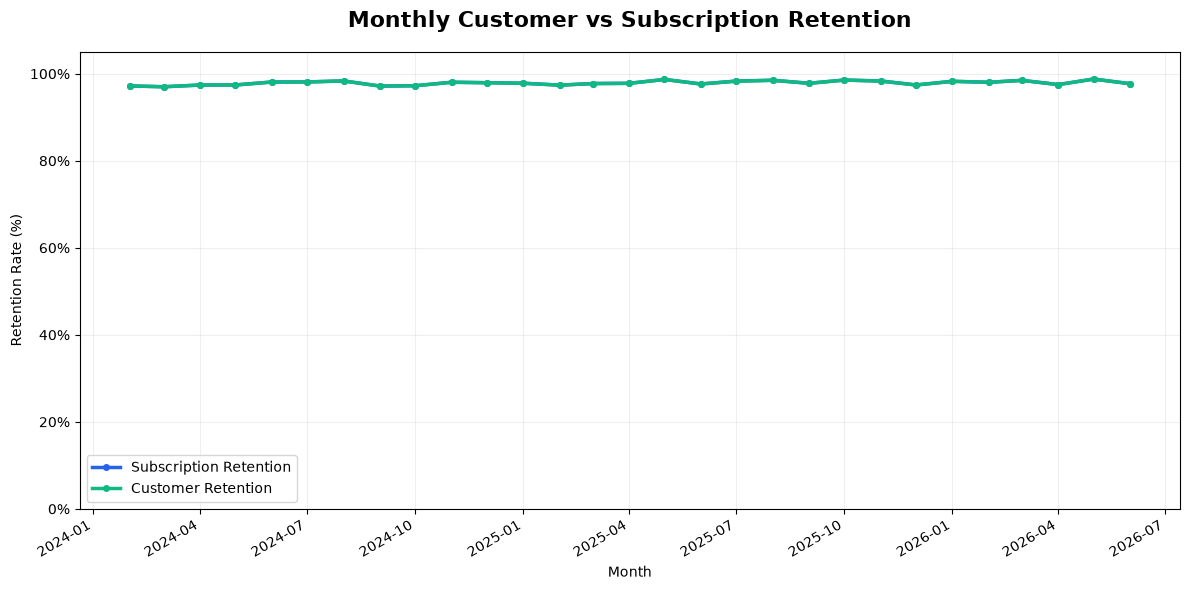

In [34]:
# Step 4.5.7 — Retention trend visualization

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plot_data = retention_comparison.copy()

plot_data["Month"] = (
    plot_data["analysis_month"].dt.to_timestamp()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    plot_data["Month"],
    plot_data["Subscription_Retention_Rate_Pct"],
    label="Subscription Retention",
    color="#2563EB",
    linewidth=2.5,
    marker="o",
    markersize=4
)

ax.plot(
    plot_data["Month"],
    plot_data["Customer_Retention_Rate_Pct"],
    label="Customer Retention",
    color="#10B981",
    linewidth=2.5,
    marker="o",
    markersize=4
)

ax.set_title(
    "Monthly Customer vs Subscription Retention",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Retention Rate (%)")
ax.set_ylim(0, 105)

ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100)
)

ax.grid(alpha=0.2)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()

retention_chart_path = (
    figures_path / "monthly_retention_comparison.png"
)

plt.savefig(
    retention_chart_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [35]:
# Step 4.5.8 — Retention business findings

valid_retention = retention_comparison.dropna(
    subset=[
        "Subscription_Retention_Rate_Pct",
        "Customer_Retention_Rate_Pct"
    ]
)

print("RETENTION BUSINESS FINDINGS")
print("=" * 70)

if not valid_retention.empty:

    latest = valid_retention.iloc[-1]

    print("Latest analyzed month:", latest["analysis_month"])

    print(
        "Subscription retention:",
        f"{latest['Subscription_Retention_Rate_Pct']:.2f}%"
    )

    print(
        "Customer retention:",
        f"{latest['Customer_Retention_Rate_Pct']:.2f}%"
    )

    print(
        "Average monthly subscription retention:",
        f"{valid_retention['Subscription_Retention_Rate_Pct'].mean():.2f}%"
    )

    print(
        "Average monthly customer retention:",
        f"{valid_retention['Customer_Retention_Rate_Pct'].mean():.2f}%"
    )

RETENTION BUSINESS FINDINGS
Latest analyzed month: 2026-06
Subscription retention: 97.72%
Customer retention: 97.72%
Average monthly subscription retention: 97.89%
Average monthly customer retention: 97.89%


In [36]:
# Step 4.5.9 — Final verification

chart_saved = (
    retention_chart_path.is_file()
    and retention_chart_path.stat().st_size > 0
)

retention_checks_pass = all(checks.values())

print("STEP 4.5 — FINAL VALIDATION")
print("=" * 65)

print("Retention checks:", retention_checks_pass)
print("Retention chart saved:", chart_saved)
print("Months analyzed:", len(retention_comparison))

if retention_checks_pass and chart_saved:
    print("\nRESULT: PASS")
else:
    print("\nRESULT: REVIEW REQUIRED")

STEP 4.5 — FINAL VALIDATION
Retention checks: True
Retention chart saved: True
Months analyzed: 30

RESULT: PASS


In [37]:
# Step 4.6.2 — Calculate opening MRR

opening_mrr = (
    monthly_df
    .groupby("analysis_month")
    .agg(
        Opening_MRR_USD=("previous_mrr_usd", "sum")
    )
    .reset_index()
    .sort_values("analysis_month")
)

print("MONTHLY OPENING MRR")
print("=" * 65)

print(opening_mrr.to_string(index=False))

MONTHLY OPENING MRR
analysis_month  Opening_MRR_USD
       2024-01             0.00
       2024-02        145853.24
       2024-03        151051.80
       2024-04        155769.21
       2024-05        163530.40
       2024-06        171524.29
       2024-07        177113.30
       2024-08        185335.76
       2024-09        192664.71
       2024-10        201173.32
       2024-11        206885.58
       2024-12        224222.88
       2025-01        232399.74
       2025-02        243134.78
       2025-03        252213.10
       2025-04        269714.65
       2025-05        284555.85
       2025-06        302151.48
       2025-07        309980.58
       2025-08        320486.34
       2025-09        329661.03
       2025-10        334086.99
       2025-11        353872.21
       2025-12        371473.83
       2026-01        387766.57
       2026-02        391973.46
       2026-03        404652.41
       2026-04        419844.14
       2026-05        432829.18
       2026-06      

In [38]:
# Step 4.6.3 — Prepare revenue retention dataset

revenue_retention = opening_mrr.merge(
    movement_mrr[
        [
            "analysis_month",
            "New_MRR",
            "Expansion_MRR",
            "Contraction_MRR",
            "Churn_MRR",
            "Reactivation_MRR",
            "Net_MRR_Change"
        ]
    ],
    on="analysis_month",
    how="inner",
    validate="one_to_one"
)

revenue_retention = revenue_retention.merge(
    monthly_mrr[
        ["analysis_month", "Total_MRR_USD"]
    ],
    on="analysis_month",
    how="inner",
    validate="one_to_one"
)

print("REVENUE RETENTION DATA")
print("=" * 100)

print(revenue_retention.to_string(index=False))

REVENUE RETENTION DATA
analysis_month  Opening_MRR_USD   New_MRR  Expansion_MRR  Contraction_MRR  Churn_MRR  Reactivation_MRR  Net_MRR_Change  Total_MRR_USD
       2024-01             0.00 145853.24           0.00            -0.00      -0.00              0.00       145853.24      145853.24
       2024-02        145853.24   6830.65        1276.20           615.40    2292.89              0.00         5198.56      151051.80
       2024-03        151051.80   2047.34        5748.80           279.40    2799.33              0.00         4717.41      155769.21
       2024-04        155769.21   5965.74        4819.65           375.20    2649.00              0.00         7761.19      163530.40
       2024-05        163530.40   3828.17        6698.50           204.00    2328.78              0.00         7993.89      171524.29
       2024-06        171524.29   3817.41        2940.90           476.45    1152.68            459.83         5589.01      177113.30
       2024-07        177113.30   3074.

In [39]:
# Step 4.6.4 — Calculate GRR and NRR

revenue_retention["GRR_Pct"] = np.where(
    revenue_retention["Opening_MRR_USD"] > 0,
    (
        revenue_retention["Opening_MRR_USD"]
        - revenue_retention["Contraction_MRR"]
        - revenue_retention["Churn_MRR"]
    )
    / revenue_retention["Opening_MRR_USD"] * 100,
    np.nan
)

revenue_retention["NRR_Pct"] = np.where(
    revenue_retention["Opening_MRR_USD"] > 0,
    (
        revenue_retention["Opening_MRR_USD"]
        + revenue_retention["Expansion_MRR"]
        - revenue_retention["Contraction_MRR"]
        - revenue_retention["Churn_MRR"]
    )
    / revenue_retention["Opening_MRR_USD"] * 100,
    np.nan
)

revenue_retention["GRR_Pct"] = (
    revenue_retention["GRR_Pct"].round(2)
)

revenue_retention["NRR_Pct"] = (
    revenue_retention["NRR_Pct"].round(2)
)

print("MONTHLY GRR AND NRR")
print("=" * 90)

print(
    revenue_retention[
        [
            "analysis_month",
            "Opening_MRR_USD",
            "GRR_Pct",
            "NRR_Pct"
        ]
    ].to_string(index=False)
)

MONTHLY GRR AND NRR
analysis_month  Opening_MRR_USD  GRR_Pct  NRR_Pct
       2024-01             0.00      NaN      NaN
       2024-02        145853.24    98.01    98.88
       2024-03        151051.80    97.96   101.77
       2024-04        155769.21    98.06   101.15
       2024-05        163530.40    98.45   102.55
       2024-06        171524.29    99.05   100.76
       2024-07        177113.30    99.19   102.91
       2024-08        185335.76    99.32   102.19
       2024-09        192664.71    98.42   100.16
       2024-10        201173.32    97.49    99.16
       2024-11        206885.58    98.86   103.24
       2024-12        224222.88    98.93    99.88
       2025-01        232399.74    98.75    99.85
       2025-02        243134.78    96.88    99.60
       2025-03        252213.10    98.36   101.94
       2025-04        269714.65    98.86   100.46
       2025-05        284555.85    99.45   102.26
       2025-06        302151.48    98.50   100.43
       2025-07        309980.5

In [40]:
# Step 4.6.5 — Revenue bridge validation

revenue_retention["Calculated_Closing_MRR"] = (
    revenue_retention["Opening_MRR_USD"]
    + revenue_retention["Net_MRR_Change"]
)

revenue_retention["Closing_MRR_Difference"] = (
    revenue_retention["Total_MRR_USD"]
    - revenue_retention["Calculated_Closing_MRR"]
)

bridge_pass = (
    revenue_retention["Closing_MRR_Difference"]
    .abs()
    .le(0.01)
    .all()
)

grr_range_pass = (
    revenue_retention["GRR_Pct"]
    .dropna()
    .between(0, 100.01)
    .all()
)

nrr_nonnegative_pass = (
    revenue_retention["NRR_Pct"]
    .dropna()
    .ge(0)
    .all()
)

nrr_vs_grr_pass = (
    revenue_retention["NRR_Pct"]
    .dropna()
    .ge(
        revenue_retention.loc[
            revenue_retention["NRR_Pct"].notna(),
            "GRR_Pct"
        ] - 0.01
    )
    .all()
)

print("GRR / NRR VALIDATION")
print("=" * 70)

print("Closing MRR bridge:", bridge_pass)
print("GRR within 0–100%:", grr_range_pass)
print("NRR nonnegative:", nrr_nonnegative_pass)
print("NRR >= GRR:", nrr_vs_grr_pass)

print(
    "\nRESULT:",
    "PASS" if all([
        bridge_pass,
        grr_range_pass,
        nrr_nonnegative_pass,
        nrr_vs_grr_pass
    ]) else "REVIEW REQUIRED"
)

GRR / NRR VALIDATION
Closing MRR bridge: True
GRR within 0–100%: True
NRR nonnegative: True
NRR >= GRR: True

RESULT: PASS


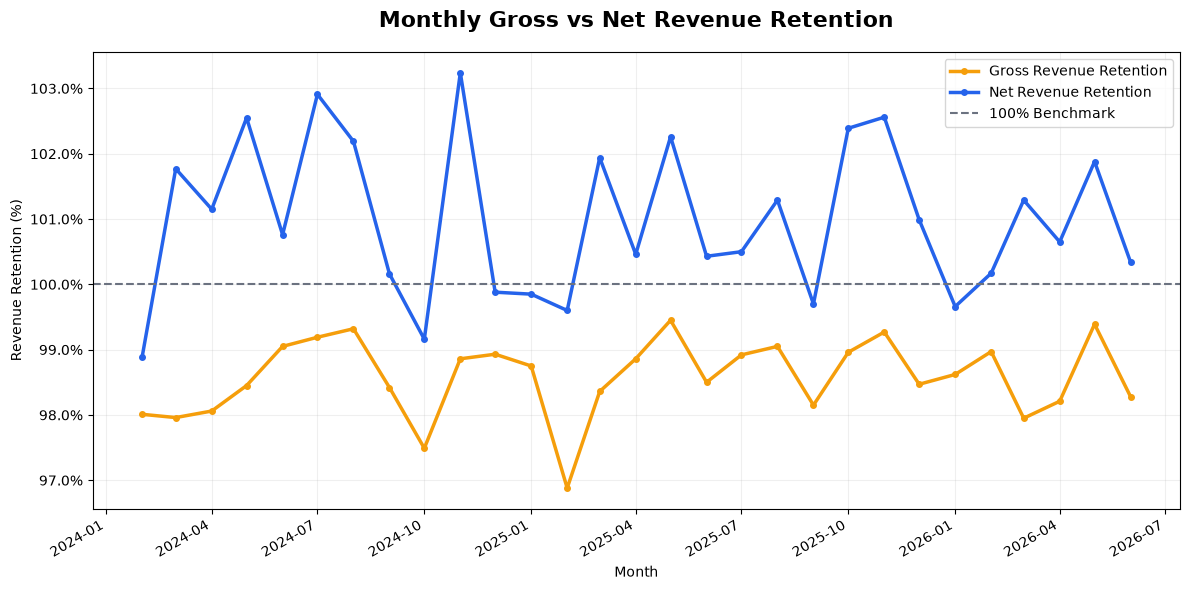

In [41]:
# Step 4.6.6 — GRR vs NRR chart

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plot_data = revenue_retention.copy()

plot_data["Month"] = (
    plot_data["analysis_month"].dt.to_timestamp()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    plot_data["Month"],
    plot_data["GRR_Pct"],
    label="Gross Revenue Retention",
    color="#F59E0B",
    linewidth=2.5,
    marker="o",
    markersize=4
)

ax.plot(
    plot_data["Month"],
    plot_data["NRR_Pct"],
    label="Net Revenue Retention",
    color="#2563EB",
    linewidth=2.5,
    marker="o",
    markersize=4
)

ax.axhline(
    100,
    linestyle="--",
    color="#6B7280",
    linewidth=1.5,
    label="100% Benchmark"
)

ax.set_title(
    "Monthly Gross vs Net Revenue Retention",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month")
ax.set_ylabel("Revenue Retention (%)")

ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100)
)

ax.grid(alpha=0.2)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()

revenue_retention_chart = (
    figures_path / "monthly_grr_nrr_comparison.png"
)

plt.savefig(
    revenue_retention_chart,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [42]:
# Step 4.6.7 — Revenue retention findings

valid_revenue_retention = revenue_retention.dropna(
    subset=["GRR_Pct", "NRR_Pct"]
)

print("GRR / NRR BUSINESS FINDINGS")
print("=" * 75)

if not valid_revenue_retention.empty:

    latest = valid_revenue_retention.iloc[-1]

    print("Latest month:", latest["analysis_month"])
    print("Latest GRR:", f"{latest['GRR_Pct']:.2f}%")
    print("Latest NRR:", f"{latest['NRR_Pct']:.2f}%")

    print(
        "Average monthly GRR:",
        f"{valid_revenue_retention['GRR_Pct'].mean():.2f}%"
    )

    print(
        "Average monthly NRR:",
        f"{valid_revenue_retention['NRR_Pct'].mean():.2f}%"
    )

    print(
        "Months with NRR above 100%:",
        int((valid_revenue_retention["NRR_Pct"] > 100).sum())
    )

GRR / NRR BUSINESS FINDINGS
Latest month: 2026-06
Latest GRR: 98.28%
Latest NRR: 100.34%
Average monthly GRR: 98.58%
Average monthly NRR: 100.99%
Months with NRR above 100%: 22


In [43]:
# Step 4.6.8 — Final verification

chart_saved = (
    revenue_retention_chart.is_file()
    and revenue_retention_chart.stat().st_size > 0
)

months_pass = (
    len(revenue_retention)
    == len(monthly_mrr)
)

checks = {
    "All months included": bool(months_pass),
    "Revenue bridge reconciled": bool(bridge_pass),
    "GRR range valid": bool(grr_range_pass),
    "NRR nonnegative": bool(nrr_nonnegative_pass),
    "NRR >= GRR": bool(nrr_vs_grr_pass),
    "Chart saved": bool(chart_saved)
}

print("STEP 4.6 — FINAL VALIDATION")
print("=" * 70)

for name, passed in checks.items():
    print(f"{name}: {passed}")

print(
    "\nRESULT:",
    "PASS" if all(checks.values()) else "REVIEW REQUIRED"
)

STEP 4.6 — FINAL VALIDATION
All months included: True
Revenue bridge reconciled: True
GRR range valid: True
NRR nonnegative: True
NRR >= GRR: True
Chart saved: True

RESULT: PASS


In [44]:
# Step 4.7.2 — Prepare monthly KPI sources

revenue_kpis = monthly_mrr[
    [
        "analysis_month",
        "Total_MRR_USD",
        "Previous_Month_MRR",
        "MRR_Change_USD",
        "MRR_Growth_Pct"
    ]
].copy()

movement_kpis = movement_mrr[
    [
        "analysis_month",
        "New_MRR",
        "Expansion_MRR",
        "Contraction_MRR",
        "Churn_MRR",
        "Reactivation_MRR",
        "Net_MRR_Change"
    ]
].copy()

churn_kpis = monthly_churn_events[
    [
        "analysis_month",
        "Opening_Paid_Subscriptions",
        "Churn_Records",
        "Customers_With_Churn_Event",
        "Subscription_Churn_Rate_Pct"
    ]
].copy()

subscription_retention_kpis = monthly_retention[
    [
        "analysis_month",
        "Retained_Subscriptions",
        "Closing_Paid_Subscriptions",
        "Subscription_Retention_Rate_Pct"
    ]
].copy()

customer_retention_kpis = monthly_customer_retention[
    [
        "analysis_month",
        "Opening_Paid_Customers",
        "Retained_Customers",
        "Closing_Paid_Customers",
        "Customer_Retention_Rate_Pct"
    ]
].copy()

revenue_retention_kpis = revenue_retention[
    [
        "analysis_month",
        "Opening_MRR_USD",
        "GRR_Pct",
        "NRR_Pct"
    ]
].copy()

print("KPI SOURCE TABLES PREPARED")
print("=" * 60)

for name, df in {
    "Revenue": revenue_kpis,
    "Movements": movement_kpis,
    "Churn": churn_kpis,
    "Subscription retention": subscription_retention_kpis,
    "Customer retention": customer_retention_kpis,
    "Revenue retention": revenue_retention_kpis
}.items():
    print(f"{name}: {len(df)} months")

KPI SOURCE TABLES PREPARED
Revenue: 30 months
Movements: 30 months
Churn: 30 months
Subscription retention: 30 months
Customer retention: 30 months
Revenue retention: 30 months


In [45]:
# Step 4.7.3 — Merge all monthly KPIs

kpi_sources = [
    movement_kpis,
    churn_kpis,
    subscription_retention_kpis,
    customer_retention_kpis,
    revenue_retention_kpis
]

saas_kpi_summary = revenue_kpis.copy()

for source in kpi_sources:
    saas_kpi_summary = saas_kpi_summary.merge(
        source,
        on="analysis_month",
        how="left",
        validate="one_to_one"
    )

saas_kpi_summary = (
    saas_kpi_summary
    .sort_values("analysis_month")
    .reset_index(drop=True)
)

print("MONTHLY SAAS KPI SUMMARY")
print("=" * 80)

print("Rows:", len(saas_kpi_summary))
print("Columns:", len(saas_kpi_summary.columns))

display(saas_kpi_summary.head())

MONTHLY SAAS KPI SUMMARY
Rows: 30
Columns: 25


,analysis_month,Total_MRR_USD,Previous_Month_MRR,MRR_Change_USD,MRR_Growth_Pct,New_MRR,Expansion_MRR,Contraction_MRR,Churn_MRR,Reactivation_MRR,...,Retained_Subscriptions,Closing_Paid_Subscriptions,Subscription_Retention_Rate_Pct,Opening_Paid_Customers,Retained_Customers,Closing_Paid_Customers,Customer_Retention_Rate_Pct,Opening_MRR_USD,GRR_Pct,NRR_Pct
0,2024-01,145853.24,NaN,NaN,NaN,145853.24,0.00,-0.0,-0.00,0.0,...,0,464,NaN,0,0,464,NaN,0.00,NaN,NaN
1,2024-02,151051.80,145853.24,5198.56,3.56,6830.65,1276.20,615.4,2292.89,0.0,...,451,468,97.20,464,451,468,97.20,145853.24,98.01,98.88
2,2024-03,155769.21,151051.80,4717.41,3.12,2047.34,5748.80,279.4,2799.33,0.0,...,454,463,97.01,468,454,463,97.01,151051.80,97.96,101.77
3,2024-04,163530.40,155769.21,7761.19,4.98,5965.74,4819.65,375.2,2649.00,0.0,...,451,465,97.41,463,451,465,97.41,155769.21,98.06,101.15
4,2024-05,171524.29,163530.40,7993.89,4.89,3828.17,6698.50,204.0,2328.78,0.0,...,453,474,97.42,465,453,474,97.42,163530.40,98.45,102.55


In [46]:
# Step 4.7.4 — Prepare reporting date

saas_kpi_summary["Month"] = (
    saas_kpi_summary["analysis_month"]
    .dt.to_timestamp()
)

saas_kpi_summary = saas_kpi_summary.drop(
    columns=["analysis_month"]
)

saas_kpi_summary = saas_kpi_summary[
    ["Month"] +
    [
        col for col in saas_kpi_summary.columns
        if col != "Month"
    ]
]

print("REPORTING DATASET PREVIEW")
print("=" * 75)

display(saas_kpi_summary.head())
print(saas_kpi_summary.dtypes)

REPORTING DATASET PREVIEW


,Month,Total_MRR_USD,Previous_Month_MRR,MRR_Change_USD,MRR_Growth_Pct,New_MRR,Expansion_MRR,Contraction_MRR,Churn_MRR,Reactivation_MRR,...,Retained_Subscriptions,Closing_Paid_Subscriptions,Subscription_Retention_Rate_Pct,Opening_Paid_Customers,Retained_Customers,Closing_Paid_Customers,Customer_Retention_Rate_Pct,Opening_MRR_USD,GRR_Pct,NRR_Pct
0,2024-01-01,145853.24,NaN,NaN,NaN,145853.24,0.00,-0.0,-0.00,0.0,...,0,464,NaN,0,0,464,NaN,0.00,NaN,NaN
1,2024-02-01,151051.80,145853.24,5198.56,3.56,6830.65,1276.20,615.4,2292.89,0.0,...,451,468,97.20,464,451,468,97.20,145853.24,98.01,98.88
2,2024-03-01,155769.21,151051.80,4717.41,3.12,2047.34,5748.80,279.4,2799.33,0.0,...,454,463,97.01,468,454,463,97.01,151051.80,97.96,101.77
3,2024-04-01,163530.40,155769.21,7761.19,4.98,5965.74,4819.65,375.2,2649.00,0.0,...,451,465,97.41,463,451,465,97.41,155769.21,98.06,101.15
4,2024-05-01,171524.29,163530.40,7993.89,4.89,3828.17,6698.50,204.0,2328.78,0.0,...,453,474,97.42,465,453,474,97.42,163530.40,98.45,102.55


Month                              datetime64[us]
Total_MRR_USD                             float64
Previous_Month_MRR                        float64
MRR_Change_USD                            float64
MRR_Growth_Pct                            float64
New_MRR                                   float64
Expansion_MRR                             float64
Contraction_MRR                           float64
Churn_MRR                                 float64
Reactivation_MRR                          float64
Net_MRR_Change                            float64
Opening_Paid_Subscriptions                  int64
Churn_Records                               int64
Customers_With_Churn_Event                  int64
Subscription_Churn_Rate_Pct               float64
Retained_Subscriptions                      int64
Closing_Paid_Subscriptions                  int64
Subscription_Retention_Rate_Pct           float64
Opening_Paid_Customers                      int64
Retained_Customers                          int64


In [47]:
# Step 4.7.5 — Validate monthly KPI summary

source_months = set(
    monthly_mrr["analysis_month"].dt.to_timestamp()
)

summary_months = set(saas_kpi_summary["Month"])

required_kpis = [
    "Total_MRR_USD",
    "New_MRR",
    "Expansion_MRR",
    "Contraction_MRR",
    "Churn_MRR",
    "Reactivation_MRR",
    "Subscription_Churn_Rate_Pct",
    "Subscription_Retention_Rate_Pct",
    "Customer_Retention_Rate_Pct",
    "GRR_Pct",
    "NRR_Pct"
]

required_kpis_present = all(
    col in saas_kpi_summary.columns
    for col in required_kpis
)

checks = {
    "Month count matches source":
        len(saas_kpi_summary) == len(monthly_mrr),

    "No duplicate months":
        not saas_kpi_summary["Month"].duplicated().any(),

    "All source months retained":
        source_months == summary_months,

    "Required KPI columns present":
        required_kpis_present,

    "No missing reporting dates":
        saas_kpi_summary["Month"].notna().all(),

    "MRR values nonnegative":
        (saas_kpi_summary["Total_MRR_USD"] >= 0).all()
}

print("FINAL KPI SUMMARY VALIDATION")
print("=" * 70)

for name, passed in checks.items():
    print(f"{name}: {bool(passed)}")

print(
    "\nRESULT:",
    "PASS" if all(checks.values()) else "REVIEW REQUIRED"
)

FINAL KPI SUMMARY VALIDATION
Month count matches source: True
No duplicate months: True
All source months retained: True
Required KPI columns present: True
No missing reporting dates: True
MRR values nonnegative: True

RESULT: PASS


In [48]:
# Step 4.7.6 — Validate merged KPI values

source_checks = {
    "MRR": (
        saas_kpi_summary["Total_MRR_USD"].sum(),
        monthly_mrr["Total_MRR_USD"].sum()
    ),
    "New MRR": (
        saas_kpi_summary["New_MRR"].sum(),
        movement_mrr["New_MRR"].sum()
    ),
    "Churn MRR": (
        saas_kpi_summary["Churn_MRR"].sum(),
        movement_mrr["Churn_MRR"].sum()
    ),
    "Churn records": (
        saas_kpi_summary["Churn_Records"].sum(),
        monthly_churn_events["Churn_Records"].sum()
    ),
    "Retained subscriptions": (
        saas_kpi_summary["Retained_Subscriptions"].sum(),
        monthly_retention["Retained_Subscriptions"].sum()
    )
}

source_values_pass = True

print("KPI SOURCE RECONCILIATION")
print("=" * 70)

for name, (summary_value, source_value) in source_checks.items():

    passed = np.isclose(
        summary_value,
        source_value,
        atol=0.01,
        rtol=0
    )

    source_values_pass = source_values_pass and passed

    print(f"{name}: {bool(passed)}")

print(
    "\nRESULT:",
    "PASS" if source_values_pass else "REVIEW REQUIRED"
)

KPI SOURCE RECONCILIATION
MRR: True
New MRR: True
Churn MRR: True
Churn records: True
Retained subscriptions: True

RESULT: PASS


In [49]:
# Step 4.7.7 — Export validated SaaS KPI summary

assert all(checks.values()), "Summary validation failed."
assert source_values_pass, "Source reconciliation failed."

processed_path.mkdir(parents=True, exist_ok=True)

output_file = (
    processed_path / "SaaS_Monthly_KPI_Summary.csv"
)

saas_kpi_summary.to_csv(
    output_file,
    index=False,
    date_format="%Y-%m-%d"
)

print("KPI SUMMARY EXPORTED SUCCESSFULLY")
print("=" * 70)

print("File:", output_file)
print("Rows:", len(saas_kpi_summary))
print("Columns:", len(saas_kpi_summary.columns))

KPI SUMMARY EXPORTED SUCCESSFULLY
File: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\data\processed\SaaS_Monthly_KPI_Summary.csv
Rows: 30
Columns: 25


In [50]:
# Step 4.7.8 — Final exported file validation

exported_df = pd.read_csv(
    output_file,
    parse_dates=["Month"]
)

export_checks = {
    "CSV exists":
        output_file.is_file(),

    "Row count matches":
        len(exported_df) == len(saas_kpi_summary),

    "Column count matches":
        len(exported_df.columns) == len(saas_kpi_summary.columns),

    "No duplicate months":
        not exported_df["Month"].duplicated().any(),

    "MRR values match":
        np.allclose(
            exported_df["Total_MRR_USD"],
            saas_kpi_summary["Total_MRR_USD"],
            atol=0.01,
            rtol=0
        ),

    "Churn counts match":
        exported_df["Churn_Records"].equals(
            saas_kpi_summary["Churn_Records"]
        )
}

print("STEP 4.7 — FINAL EXPORT VALIDATION")
print("=" * 70)

for name, passed in export_checks.items():
    print(f"{name}: {bool(passed)}")

print(
    "\nRESULT:",
    "PASS" if all(export_checks.values()) else "REVIEW REQUIRED"
)

STEP 4.7 — FINAL EXPORT VALIDATION
CSV exists: True
Row count matches: True
Column count matches: True
No duplicate months: True
MRR values match: True
Churn counts match: True

RESULT: PASS


In [51]:
# Step 4.8.2 — Extract final SaaS KPI findings

summary = saas_kpi_summary.sort_values("Month").copy()

latest = summary.iloc[-1]

highest_mrr = summary.loc[
    summary["Total_MRR_USD"].idxmax()
]

highest_churn = summary.loc[
    summary["Subscription_Churn_Rate_Pct"].idxmax()
]

valid_nrr = summary.dropna(subset=["NRR_Pct"])

findings = {
    "months_analyzed": len(summary),
    "latest_month": latest["Month"].strftime("%Y-%m"),
    "latest_mrr": latest["Total_MRR_USD"],
    "latest_grr": latest["GRR_Pct"],
    "latest_nrr": latest["NRR_Pct"],
    "latest_subscription_churn": latest[
        "Subscription_Churn_Rate_Pct"
    ],
    "latest_subscription_retention": latest[
        "Subscription_Retention_Rate_Pct"
    ],
    "latest_customer_retention": latest[
        "Customer_Retention_Rate_Pct"
    ],
    "highest_mrr_month": highest_mrr[
        "Month"
    ].strftime("%Y-%m"),
    "highest_mrr_value": highest_mrr["Total_MRR_USD"],
    "highest_churn_month": highest_churn[
        "Month"
    ].strftime("%Y-%m"),
    "highest_churn_rate": highest_churn[
        "Subscription_Churn_Rate_Pct"
    ],
    "months_nrr_above_100": int(
        (valid_nrr["NRR_Pct"] > 100).sum()
    )
}

print("FINAL SAAS KPI BUSINESS FINDINGS")
print("=" * 75)

for key, value in findings.items():
    print(f"{key}: {value}")

FINAL SAAS KPI BUSINESS FINDINGS
months_analyzed: 30
latest_month: 2026-06
latest_mrr: 465561.26
latest_grr: 98.28
latest_nrr: 100.34
latest_subscription_churn: 2.28
latest_subscription_retention: 97.72
latest_customer_retention: 97.72
highest_mrr_month: 2026-06
highest_mrr_value: 465561.26
highest_churn_month: 2024-03
highest_churn_rate: 2.99
months_nrr_above_100: 22


In [52]:
# Step 4.8.3 — Generate KPI business findings report

from pathlib import Path

reports_path = project_root / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

report_file = reports_path / "SaaS_KPI_Business_Findings.md"

def fmt_money(value):
    return "N/A" if pd.isna(value) else f"${value:,.2f}"

def fmt_pct(value):
    return "N/A" if pd.isna(value) else f"{value:.2f}%"

report_content = f"""# SaaS Revenue & Subscription Analytics
## Revenue KPI Analysis — Business Findings

### 1. Executive Summary

This report presents validated monthly SaaS revenue,
churn, and retention KPIs calculated using Python
and Pandas.

The analysis covers {findings['months_analyzed']} months.

### 2. Latest Monthly KPI Snapshot

**Reporting Month:** {findings['latest_month']}

| KPI | Value |
|---|---:|
| Monthly Recurring Revenue | {fmt_money(findings['latest_mrr'])} |
| Gross Revenue Retention | {fmt_pct(findings['latest_grr'])} |
| Net Revenue Retention | {fmt_pct(findings['latest_nrr'])} |
| Subscription Churn Rate | {fmt_pct(findings['latest_subscription_churn'])} |
| Subscription Retention Rate | {fmt_pct(findings['latest_subscription_retention'])} |
| Customer Retention Rate | {fmt_pct(findings['latest_customer_retention'])} |

### 3. Key Revenue Findings

- Highest recorded MRR month:
  {findings['highest_mrr_month']}
- Highest recorded monthly MRR:
  {fmt_money(findings['highest_mrr_value'])}
- Latest recorded monthly MRR:
  {fmt_money(findings['latest_mrr'])}
- Months with NRR above 100%:
  {findings['months_nrr_above_100']}

### 4. Churn Findings

- Highest observed subscription churn-rate month:
  {findings['highest_churn_month']}
- Highest observed subscription churn rate:
  {fmt_pct(findings['highest_churn_rate'])}

The subscription churn rate uses subscriptions with
positive previous MRR as the observed opening paid base.

### 5. Revenue Retention Interpretation

GRR measures recurring revenue retained from the
opening paid base after contraction and churn.

NRR also includes expansion from that opening base.

An NRR above 100% indicates that expansion exceeded
contraction and churn for that month, under the
implemented metric definition.

### 6. KPI Visualizations

![MRR Trend](figures/monthly_mrr_trend.png)

![MRR Movements](figures/monthly_mrr_movements.png)

![Subscription Churn](figures/monthly_subscription_churn_rate.png)

![Customer vs Subscription Retention](figures/monthly_retention_comparison.png)

![GRR vs NRR](figures/monthly_grr_nrr_comparison.png)

### 7. Validation Summary

The Python KPI workflow completed the following checks:

- Monthly MRR aggregation reconciled with source data.
- MRR movement totals reconciled with source deltas.
- Revenue movements reconciled with monthly closing MRR.
- Churn and retention rates passed range and base checks.
- GRR and NRR passed revenue bridge and rate checks.
- The processed KPI summary was exported and verified.

### 8. Business Recommendations

1. Investigate months with elevated subscription churn.
2. Compare expansion revenue against contraction
   and churn losses.
3. Examine differences between customer retention
   and subscription retention.
4. Investigate periods where NRR falls below 100%.
5. Segment these metrics by customer cohorts and
   subscription plans in future analysis.

These are investigation priorities, not proven
causal explanations.

### 9. Limitations

- The source dataset is synthetic.
- Retention metrics depend on observed monthly records.
- Monthly MRR is a recurring revenue balance,
  not recognized revenue for the year.
- Customer churn events do not necessarily mean
  complete customer-level churn.
- Cohort analysis and customer acquisition cost
  are outside the scope of this report.

### 10. Processed Dataset

`data/processed/SaaS_Monthly_KPI_Summary.csv`
"""

report_file.write_text(
    report_content,
    encoding="utf-8"
)

print("KPI BUSINESS FINDINGS REPORT CREATED")
print("File:", report_file)

KPI BUSINESS FINDINGS REPORT CREATED
File: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\SaaS_KPI_Business_Findings.md


In [53]:
# Step 4.8.4 — Final Week 2 Python KPI verification

required_files = [
    project_root / "docs" / "SaaS_KPI_Definitions.md",
    project_root / "reports" / "SaaS_KPI_Business_Findings.md",
    project_root / "data" / "processed"
    / "SaaS_Monthly_KPI_Summary.csv",
    figures_path / "monthly_mrr_trend.png",
    figures_path / "monthly_mrr_movements.png",
    figures_path / "monthly_subscription_churn_rate.png",
    figures_path / "monthly_retention_comparison.png",
    figures_path / "monthly_grr_nrr_comparison.png"
]

print("WEEK 2 PYTHON KPI DELIVERABLE VERIFICATION")
print("=" * 75)

all_files_pass = True

for file in required_files:
    exists = file.is_file() and file.stat().st_size > 0 \
        if file.is_file() else False

    all_files_pass = all_files_pass and exists

    print(
        "PASS" if exists else "FAIL",
        "|",
        file.relative_to(project_root)
    )

print("=" * 75)

print(
    "RESULT:",
    "PASS" if all_files_pass else "REVIEW REQUIRED"
)

WEEK 2 PYTHON KPI DELIVERABLE VERIFICATION
PASS | docs\SaaS_KPI_Definitions.md
PASS | reports\SaaS_KPI_Business_Findings.md
PASS | data\processed\SaaS_Monthly_KPI_Summary.csv
PASS | reports\figures\monthly_mrr_trend.png
PASS | reports\figures\monthly_mrr_movements.png
PASS | reports\figures\monthly_subscription_churn_rate.png
PASS | reports\figures\monthly_retention_comparison.png
PASS | reports\figures\monthly_grr_nrr_comparison.png
RESULT: PASS


In [54]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent

interim_path = project_root / "data" / "interim"

tables = [
    "plans",
    "customers",
    "subscriptions",
    "subscription_months",
    "invoices"
]

for table in tables:

    file_path = interim_path / f"{table}_cleaned.csv"

    df = pd.read_csv(file_path)

    print(f"\n{'=' * 70}")
    print(f"TABLE: {table}")
    print(f"ROWS: {len(df)}")
    print(f"{'=' * 70}")

    for column in df.columns:
        print(f"{column:35} {str(df[column].dtype)}")


TABLE: plans
ROWS: 10
plan_id                             str
plan_name                           str
tier                                str
billing_interval                    str
list_price_usd                      int64
monthly_price_usd                   float64
billing_months                      int64
seats_included                      int64
extra_seat_price_usd                int64
is_active                           str
launched_date                       str

TABLE: customers
ROWS: 1200
customer_id                         str
company_name                        str
country                             str
region                              str
industry                            str
segment                             str
employees_band                      str
signup_date                         str
acquisition_channel                 str
cohort_month                        str
customer_status                     str
churn_date                          str

TABLE: subscrip

In [55]:
# Inspect ID columns and their uniqueness

for table in tables:

    df = pd.read_csv(
        interim_path / f"{table}_cleaned.csv"
    )

    print(f"\nTABLE: {table}")
    print("-" * 65)

    id_columns = [
        col for col in df.columns
        if col.lower().endswith("_id")
    ]

    for col in id_columns:

        print(
            f"{col}: "
            f"unique={df[col].nunique(dropna=True)}, "
            f"missing={df[col].isna().sum()}, "
            f"rows={len(df)}"
        )


TABLE: plans
-----------------------------------------------------------------
plan_id: unique=10, missing=0, rows=10

TABLE: customers
-----------------------------------------------------------------
customer_id: unique=1200, missing=0, rows=1200

TABLE: subscriptions
-----------------------------------------------------------------
subscription_id: unique=1381, missing=0, rows=1381
customer_id: unique=1200, missing=0, rows=1381
plan_id: unique=10, missing=0, rows=1381

TABLE: subscription_months
-----------------------------------------------------------------
record_id: unique=19015, missing=0, rows=19015
customer_id: unique=1200, missing=0, rows=19015
subscription_id: unique=1381, missing=0, rows=19015
plan_id: unique=10, missing=0, rows=19015

TABLE: invoices
-----------------------------------------------------------------
invoice_id: unique=11257, missing=0, rows=11257
customer_id: unique=1192, missing=0, rows=11257
subscription_id: unique=1368, missing=0, rows=11257


In [56]:
import pandas as pd

tables = [
    "plans",
    "customers",
    "subscriptions",
    "subscription_months",
    "invoices"
]

for table in tables:

    df = pd.read_csv(
        interim_path / f"{table}_cleaned.csv"
    )

    print(f"\n{'=' * 60}")
    print(f"TABLE: {table}")
    print(f"{'=' * 60}")

    for col in df.columns:
        print(f"{col}: {df[col].dtype}")


TABLE: plans
plan_id: str
plan_name: str
tier: str
billing_interval: str
list_price_usd: int64
monthly_price_usd: float64
billing_months: int64
seats_included: int64
extra_seat_price_usd: int64
is_active: str
launched_date: str

TABLE: customers
customer_id: str
company_name: str
country: str
region: str
industry: str
segment: str
employees_band: str
signup_date: str
acquisition_channel: str
cohort_month: str
customer_status: str
churn_date: str

TABLE: subscriptions
subscription_id: str
customer_id: str
plan_id: str
start_date: str
end_date: str
subscription_status: str
billing_interval: str
seats: int64
discount_pct: int64
mrr_usd: float64
contract_term_months: int64
auto_renew: str

TABLE: subscription_months
record_id: str
customer_id: str
subscription_id: str
plan_id: str
period_month: str
month_start_date: str
is_active: str
seats: int64
mrr_usd: float64
previous_mrr_usd: float64
mrr_delta_usd: float64
movement_type: str
tenure_months: int64
cohort_month: str
currency: str

TABL

In [57]:
import pandas as pd

tables = [
    "plans",
    "customers",
    "subscriptions",
    "subscription_months",
    "invoices"
]

schema_lines = []

for table in tables:
    df = pd.read_csv(
        interim_path / f"{table}_cleaned.csv"
    )

    schema_lines.append(f"\nTABLE: {table}")

    for col in df.columns:
        schema_lines.append(f"{col}: {df[col].dtype}")

schema_text = "\n".join(schema_lines)

print(schema_text)


TABLE: plans
plan_id: str
plan_name: str
tier: str
billing_interval: str
list_price_usd: int64
monthly_price_usd: float64
billing_months: int64
seats_included: int64
extra_seat_price_usd: int64
is_active: str
launched_date: str

TABLE: customers
customer_id: str
company_name: str
country: str
region: str
industry: str
segment: str
employees_band: str
signup_date: str
acquisition_channel: str
cohort_month: str
customer_status: str
churn_date: str

TABLE: subscriptions
subscription_id: str
customer_id: str
plan_id: str
start_date: str
end_date: str
subscription_status: str
billing_interval: str
seats: int64
discount_pct: int64
mrr_usd: float64
contract_term_months: int64
auto_renew: str

TABLE: subscription_months
record_id: str
customer_id: str
subscription_id: str
plan_id: str
period_month: str
month_start_date: str
is_active: str
seats: int64
mrr_usd: float64
previous_mrr_usd: float64
mrr_delta_usd: float64
movement_type: str
tenure_months: int64
cohort_month: str
currency: str

TABL

In [58]:
import pandas as pd
from pathlib import Path

tables = [
    "plans",
    "customers",
    "subscriptions",
    "subscription_months",
    "invoices"
]

schema_rows = []

for table in tables:
    df = pd.read_csv(
        interim_path / f"{table}_cleaned.csv"
    )

    for col in df.columns:
        schema_rows.append({
            "table_name": table,
            "column_name": col,
            "pandas_dtype": str(df[col].dtype),
            "sample_value": (
                str(df[col].dropna().iloc[0])
                if df[col].notna().any()
                else ""
            )
        })

schema_df = pd.DataFrame(schema_rows)

output_file = (
    project_root / "docs" / "PostgreSQL_Source_Schema.csv"
)

schema_df.to_csv(output_file, index=False)

print("Schema file created:", output_file)
print("Total columns:", len(schema_df))
print("Tables:", schema_df["table_name"].nunique())

Schema file created: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\docs\PostgreSQL_Source_Schema.csv
Total columns: 67
Tables: 5


In [59]:
import pandas as pd

tables = [
    "plans",
    "customers",
    "subscriptions",
    "subscription_months",
    "invoices"
]

for table in tables:
    df = pd.read_csv(
        interim_path / f"{table}_cleaned.csv"
    )

    print(f"{table}: {len(df)} rows, {len(df.columns)} columns")

plans: 10 rows, 11 columns
customers: 1200 rows, 12 columns
subscriptions: 1381 rows, 12 columns
subscription_months: 19015 rows, 15 columns
invoices: 11257 rows, 17 columns


In [61]:
from pathlib import Path

file_path = project_root / "docs" / "PostgreSQL_Table_Columns.csv"

print("Expected path:", file_path)
print("File exists:", file_path.exists())

print("\nFiles currently in docs folder:")
for file in (project_root / "docs").iterdir():
    print(file.name)

Expected path: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\docs\PostgreSQL_Table_Columns.csv
File exists: False

Files currently in docs folder:
.gitkeep
Dataset_Inventory.md
Dataset_Schema.csv
Data_Dictionary.md
PostgreSQL_Source_Schema.csv
SaaS_KPI_Definitions.md


In [62]:
import pandas as pd

file_path = project_root / "docs" / "PostgreSQL_Table_Columns.csv"

print("File exists:", file_path.exists())

if file_path.exists():
    sql_schema = pd.read_csv(file_path)
    print("Total rows:", len(sql_schema))
    print("Columns:", sql_schema.columns.tolist())

File exists: True
Total rows: 67
Columns: ['table_name', 'ordinal_position', 'column_name']


In [63]:
import pandas as pd

sql_schema = pd.read_csv(
    project_root / "docs" / "PostgreSQL_Table_Columns.csv"
)

tables = [
    "plans",
    "customers",
    "subscriptions",
    "subscription_months",
    "invoices"
]

all_match = True

for table in tables:
    csv_columns = pd.read_csv(
        interim_path / f"{table}_cleaned.csv",
        nrows=0
    ).columns.tolist()

    sql_columns = (
        sql_schema[sql_schema["table_name"] == table]
        .sort_values("ordinal_position")["column_name"]
        .tolist()
    )

    match = csv_columns == sql_columns

    print(f"\nTABLE: {table}")
    print("CSV columns:", len(csv_columns))
    print("SQL columns:", len(sql_columns))
    print("Column order match:", match)

    if not match:
        all_match = False

        for i in range(max(len(csv_columns), len(sql_columns))):
            csv_col = csv_columns[i] if i < len(csv_columns) else "<MISSING>"
            sql_col = sql_columns[i] if i < len(sql_columns) else "<MISSING>"

            if csv_col != sql_col:
                print(
                    f"Position {i + 1}: "
                    f"CSV={csv_col}, SQL={sql_col}"
                )

print("\nFINAL RESULT:", "PASS" if all_match else "FAIL")


TABLE: plans
CSV columns: 11
SQL columns: 11
Column order match: True

TABLE: customers
CSV columns: 12
SQL columns: 12
Column order match: True

TABLE: subscriptions
CSV columns: 12
SQL columns: 12
Column order match: True

TABLE: subscription_months
CSV columns: 15
SQL columns: 15
Column order match: True

TABLE: invoices
CSV columns: 17
SQL columns: 17
Column order match: True

FINAL RESULT: PASS
